In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import h5py as h5
import os

In [10]:
# get present working directory
cwd = os.getcwd()
cwd

'/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/analyse_input_features'

In [8]:
data_dir = "/home/jake/Documents/AI_Clinician/choc_data/combined_data/hourly_all_patients/split_0/training_set"

In [11]:
# load train.h5 file
train_file_path = os.path.join(data_dir, "train.h5")
train_file = h5.File(train_file_path, "r")
with h5.File(train_file_path, "r") as train_file:
    # List all groups
    print("Keys: %s" % train_file.keys())

Keys: <KeysViewHDF5 ['feature_names', 'index_ptr', 'stay_ids', 'trajectories']>


In [13]:
# load feature_names, index_ptr, stay_ids and trajectories
with h5.File(train_file_path, "r") as train_file:
    feature_names = train_file["feature_names"][:]
    index_ptr = train_file["index_ptr"][:]
    stay_ids = train_file["stay_ids"][:]
    trajectories = train_file["trajectories"][:]

In [15]:
# print features names, stored as bytes, so decode to string
feature_names = [name.decode("utf-8") for name in feature_names]
for name in feature_names:
    print(name)

airway_type
airway_type_mask
airway_type_delta
breath_sequence
breath_sequence_mask
breath_sequence_delta
control_variable
control_variable_mask
control_variable_delta
expiratory_pressure
expiratory_pressure_mask
expiratory_pressure_delta
fio2
fio2_mask
fio2_delta
inspiratory_time
inspiratory_time_mask
inspiratory_time_delta
mean_airway_pressure
mean_airway_pressure_mask
mean_airway_pressure_delta
mode_of_ventilation
mode_of_ventilation_mask
mode_of_ventilation_delta
nitric_oxide
nitric_oxide_mask
nitric_oxide_delta
oxygen_flow
oxygen_flow_mask
oxygen_flow_delta
peep
peep_mask
peep_delta
pip
pip_mask
pip_delta
weight_kg
ecls_support_type
on_ecls
furosemide
hydralazine
labetalol
nitroglycerin
nitroprusside
intake
output
alt
alt_mask
alt_delta
calcium
calcium_mask
calcium_delta
chloride
chloride_mask
chloride_delta
creatinine
creatinine_mask
creatinine_delta
crp
crp_mask
crp_delta
hematocrit
hematocrit_mask
hematocrit_delta
hemoglobin
hemoglobin_mask
hemoglobin_delta
neutrophil_count
neu

In [16]:
n_features = len(feature_names)
print(f"Number of features: {n_features}")

Number of features: 155


In [17]:
print("trajectories.shape):", trajectories.shape)


trajectories.shape): (5694306, 155)


In [19]:
# find intake feature index
intake_feature_index = feature_names.index("intake")
print(f"Index of 'intake' feature: {intake_feature_index}")

Index of 'intake' feature: 44


In [18]:
# find vis feature index
vis_feature_index = feature_names.index("vis")
print(f"Index of 'vis' feature: {vis_feature_index}")

Index of 'vis' feature: 146


In [22]:
intake = trajectories[:, intake_feature_index]
intake

array([ 0.,  0.,  3., ...,  0.,  0., 30.], dtype=float32)

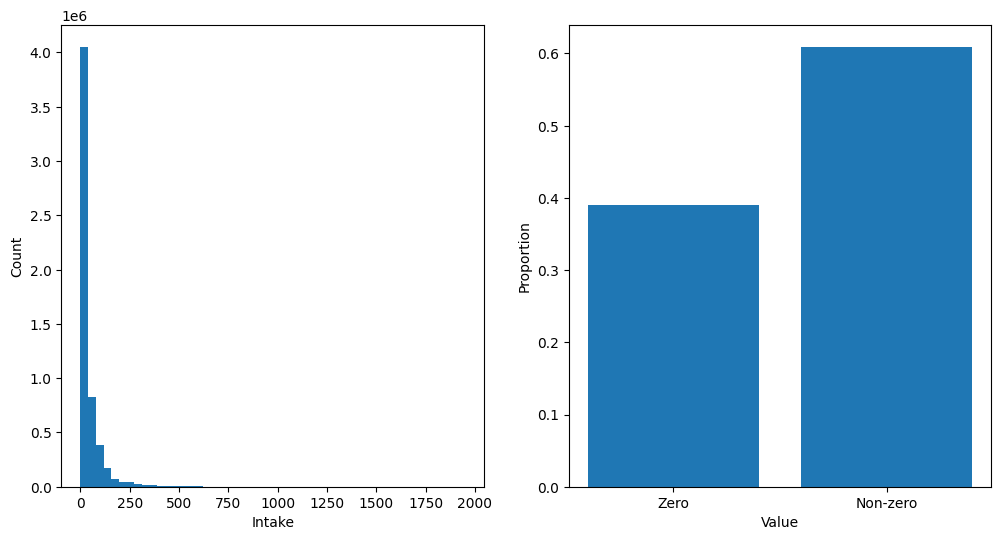

In [27]:
# plot full distribution of intake values is subplot on left
plt.subplot(1, 2, 1)
plt.hist(intake, bins=50)
plt.xlabel("Intake")
plt.ylabel("Count")

# plot a histogram of number of zero and non-zero values is two bars on the right subplot
total_count = len(intake)
n_zeros = np.sum(intake == 0)
n_non_zeros = np.sum(intake != 0)
proportion_zeros = n_zeros / total_count
proportion_non_zeros = n_non_zeros / total_count

plt.subplot(1, 2, 2)
plt.bar(["Zero", "Non-zero"], [proportion_zeros, proportion_non_zeros])
plt.ylabel("Proportion") 
plt.xlabel("Value")

# make the figure wider
plt.gcf().set_size_inches(12, 6)

Text(0.5, 1.0, 'Distribution of non-zero intake values')

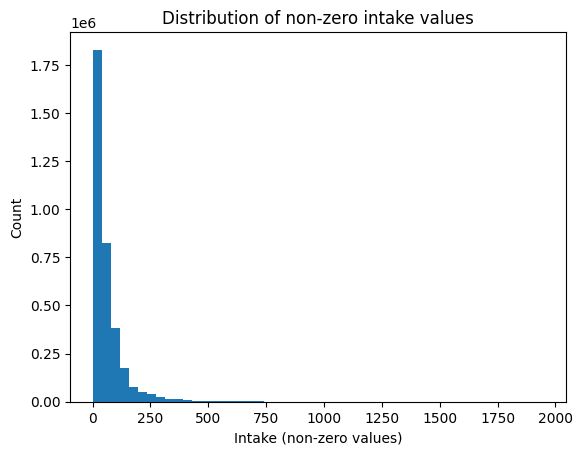

In [28]:

# plot the distribution of intake values for non-zero values only
non_zero_intake = intake[intake != 0]
plt.figure()
plt.hist(non_zero_intake, bins=50)
plt.xlabel("Intake (non-zero values)")
plt.ylabel("Count")
plt.title("Distribution of non-zero intake values")


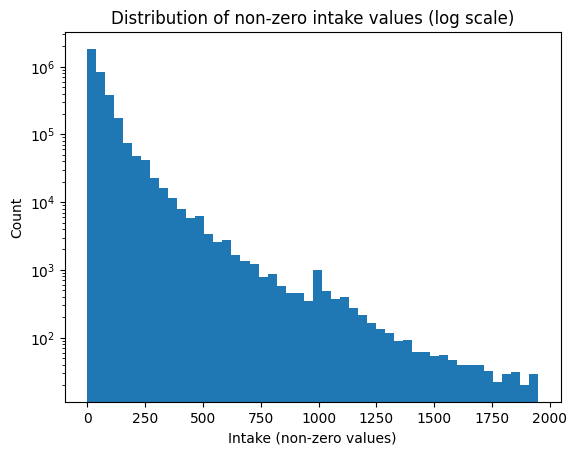

In [29]:
# plot the distribution of intake values for non-zero values only on log scale
plt.figure()
plt.hist(non_zero_intake, bins=50)
plt.xlabel("Intake (non-zero values)")
plt.ylabel("Count")
plt.title("Distribution of non-zero intake values (log scale)")
plt.yscale("log")

In [30]:
# print mean, median, std, min, max of intake values for non-zero values only
mean_intake = np.mean(non_zero_intake)
median_intake = np.median(non_zero_intake)
std_intake = np.std(non_zero_intake)
min_intake = np.min(non_zero_intake)
max_intake = np.max(non_zero_intake)
print(f"Mean of non-zero intake values: {mean_intake}")
print(f"Median of non-zero intake values: {median_intake}")
print(f"Standard deviation of non-zero intake values: {std_intake}")
print(f"Minimum of non-zero intake values: {min_intake}")   
print(f"Maximum of non-zero intake values: {max_intake}")   

Mean of non-zero intake values: 60.17668151855469
Median of non-zero intake values: 35.0
Standard deviation of non-zero intake values: 87.2989273071289
Minimum of non-zero intake values: 0.0010000000474974513
Maximum of non-zero intake values: 1948.550048828125


In [34]:
# load train_dynamic_deephit_dataset.h5 file
train_dynamic_deephit_dataset_file_path = os.path.join(data_dir, "train_dynamic_deephit_dataset.h5")
train_dynamic_deephit_dataset_file = h5.File(train_dynamic_deephit_dataset_file_path, "r")
with h5.File(train_dynamic_deephit_dataset_file_path, "r") as train_dynamic_deephit_dataset_file:
    # List all groups
    print("Keys: %s" % train_dynamic_deephit_dataset_file.keys())
    feature_names = train_dynamic_deephit_dataset_file["feature_names"][:]
    trajectories = train_dynamic_deephit_dataset_file["trajectories"][:]

Keys: <KeysViewHDF5 ['carry_forward_ind', 'event', 'feature_dim', 'feature_names', 'index_ptr', 'physiological_feature_ind', 'physiological_feature_type', 'response_zero_ind', 'stay_ids', 'time_to_event', 'time_to_event_raw', 'trajectories']>


In [ ]:
# get intake and vis feature indices from feature_names array
feature_names_str = np.asarray(feature_names).astype(str)

intake_matches = np.where(feature_names_str == "intake")[0]
vis_matches = np.where(feature_names_str == "vis")[0]

if intake_matches.size == 0:
    raise ValueError("'intake' not found in feature_names")
if vis_matches.size == 0:
    raise ValueError("'vis' not found in feature_names")

intake_feature_index = int(intake_matches[0])
vis_feature_index = int(vis_matches[0])

AttributeError: 'numpy.ndarray' object has no attribute 'index'

In [33]:
# get features from trajectories
intake = trajectories[:, intake_feature_index]
vis = trajectories[:, vis_feature_index]

KeyError: 'Unable to synchronously open object (invalid identifier type to function)'